In [1]:
#importing required packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers import Dropout

In [2]:
#loading the dataset

dataset = pd.read_csv(r"C:\Users\priya\Downloads\data_mv_set.csv")
dataset

,uuid,exchange,ask_price,ask_whole_lot_volume,ask_lot_volume,bid_price,bid_whole_lot_volume,bid_lot_volume,close_price,close_volume,volume_avg_today,volume_avg_24h,trades_today,trades_24h,low_today,low_24h,high_today,high_24h,opening_price,ts
0,9831925d-f9b1-4fde-9d40-34c5dc222a91,kraken,0.000804,289,289,0.000802,150,150,0.000805,150,94508.35523,176635.04970,1087,2278,0.000787,0.000787,0.000855,0.000855,0.000802,25569.50487
1,63644912-c186-4a7c-a0fd-739520c879b6,kraken,0.000804,334,334,0.000802,150,150,0.000805,150,103094.91810,176635.04970,1196,2278,0.000787,0.000787,0.000855,0.000855,0.000802,25569.50487
2,8150086e-98d8-4dd3-91fa-111923a6f78c,kraken,0.000804,289,289,0.000802,150,150,0.000805,150,103094.95470,176635.04970,1198,2278,0.000787,0.000787,0.000855,0.000855,0.000802,25569.50487
3,6df11107-1be2-4e31-97a6-d20e80431b14,kraken,0.000804,134,134,0.000802,150,150,0.000805,150,103249.37390,176635.04970,1199,2278,0.000787,0.000787,0.000855,0.000855,0.000802,25569.50487
4,2d2358d9-dec6-49be-b309-33db96b75eaa,kraken,0.000804,134,134,0.000802,150,150,0.000805,150,103279.59390,176635.04970,1200,2278,0.000787,0.000787,0.000855,0.000855,0.000802,25569.50487
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33294,9878b542-05bd-4aa4-95e5-c908f4749423,kraken,0.000795,890,890,0.000792,559,559,0.000791,559,30790.47498,73108.65545,399,927,0.000755,0.000736,0.000803,0.000803,0.000766,25569.50491
33295,a15e323b-9e41-425f-b3e0-eeded8ac92b0,kraken,0.000795,890,890,0.000793,604,604,0.000791,604,30976.58482,73108.65545,403,927,0.000755,0.000736,0.000803,0.000803,0.000766,25569.50491
33296,fa7c1391-d89a-4620-bd51-c891277e92b5,kraken,0.000795,890,890,0.000792,559,559,0.000791,559,28224.59962,73108.65545,357,927,0.000755,0.000736,0.000803,0.000803,0.000766,25569.50491
33297,2d547e7c-0840-4cbe-b112-25c05e4916db,kraken,0.000795,890,890,0.000792,288,288,0.000791,288,30903.20445,73108.65545,402,927,0.000755,0.000736,0.000803,0.000803,0.000766,25569.50491


In [3]:
#removing the rows we are not interested in

del dataset['uuid']
del dataset['exchange']
del dataset['volume_avg_today']
del dataset['volume_avg_24h']
del dataset['trades_today']
del dataset['trades_24h']
del dataset['low_today']
del dataset['low_24h']
del dataset['high_today']
del dataset['high_24h']
del dataset['opening_price']

In [4]:
#test and train

trainrows=int(dataset.shape[0]*.8)-1

In [5]:
train=dataset.iloc[:trainrows, :]
test=dataset.iloc[trainrows:, :]

In [6]:
print(train.shape)
print(test.shape)

(26638, 9)
(6661, 9)


In [7]:
#normalise features

sc=MinMaxScaler(feature_range=(0,1))
training_set_scaled=sc.fit_transform(train.values)
test_set_scaled=sc.fit_transform(test.values)

In [8]:
#prepare Training data

steps=50

In [9]:
x_train=[]
y_train=[]
for i in range(steps, training_set_scaled.shape[0]-steps):
    x_train.append(training_set_scaled[i-steps:i, :])
    y_train.append(training_set_scaled[i, :])
    
x_train, y_train=np.array(x_train), np.array(y_train)
print(x_train.shape)

(26538, 50, 9)


In [10]:
#prepare test data

x_test=[]
y_test=[]
for i in range(steps, test_set_scaled.shape[0]):
    x_test.append(test_set_scaled[i-steps:i, :])
    y_test.append(test_set_scaled[i, :])
    
x_test, y_test=np.array(x_test),np.array(y_test)
print(x_test.shape)

(6611, 50, 9)


In [11]:
#train the model

model=Sequential()

In [12]:
epochs = 15

model.add(LSTM(units=50, return_sequences = True, input_shape = (x_train.shape[1],9)))
model.add(Dropout(0.2))
model.add(LSTM(units=50, return_sequences = True))
model.add(Dropout(0.2))
model.add(LSTM(units=50, return_sequences = True))
model.add(Dropout(0.2))
model.add(LSTM(units=50))
model.add(Dropout(0.2))
model.add(Dense(units=9))
model.compile(loss="mse", optimizer="adam", metrics = ['accuracy'])
model.fit(x_train, y_train, batch_size = 32, epochs = epochs)
model.summary

model.save("multiple_features_"+str(steps)+"_steps_"+str(epochs)+"_epochs.h5")
print("Saved model to disk")


Epoch 1/15


830/830 [==============================] - 58s 64ms/step - loss: 0.0325 - accuracy: 0.5926
Epoch 2/15
830/830 [==============================] - 51s 62ms/step - loss: 0.0255 - accuracy: 0.6387
Epoch 3/15
830/830 [==============================] - 53s 64ms/step - loss: 0.0231 - accuracy: 0.6704
Epoch 4/15
830/830 [==============================] - 49s 59ms/step - loss: 0.0224 - accuracy: 0.6964
Epoch 5/15
830/830 [==============================] - 50s 60ms/step - loss: 0.0221 - accuracy: 0.7102
Epoch 6/15
830/830 [==============================] - 50s 60ms/step - loss: 0.0220 - accuracy: 0.7119
Epoch 7/15
830/830 [==============================] - 49s 59ms/step - loss: 0.0218 - accuracy: 0.7166
Epoch 8/15
830/830 [==============================] - 48s 57ms/step - loss: 0.0218 - accuracy: 0.7173
Epoch 9/15
830/830 [==============================] - 51s 62ms/step - loss: 0.0218 - accuracy: 0.7153
Epoch 10/15
830/830 [==============================] - 21645s 26s/step - loss: 

C:\Users\priya\anaconda3\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [45]:
# Evaluate on test data


results=model.evaluate(x_test,y_test,batch_size=32)
print("test loss, test acc:",results)



# Evaluate on test data
207/207 [==============================] - 2s 12ms/step - loss: 0.0156
test loss, test acc: 0.015595940873026848


In [21]:

#predict values from the test data trained using train data

y_hat=model.predict(x_test)
y_hat=sc.inverse_transform(y_hat)
y_test=test[steps:].reset_index()

207/207 [==============================] - 3s 12ms/step


In [24]:
#print(accuracy_score(y_test, y_hat))

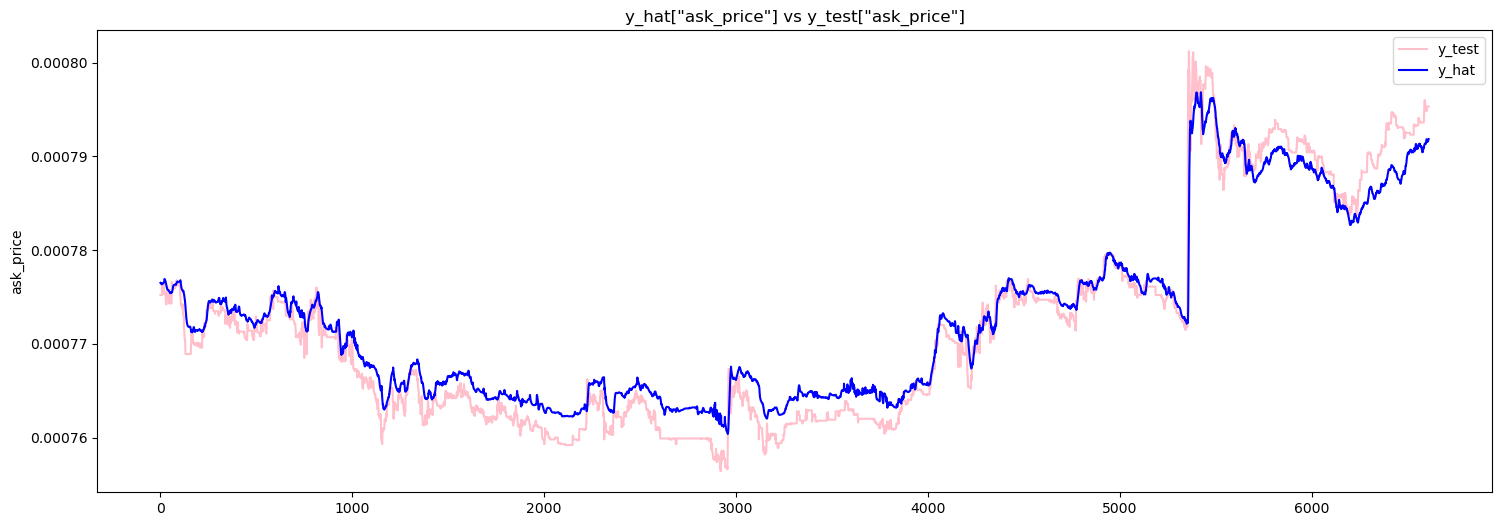

In [25]:
# visualize ask-price prediction

plt.figure(figsize=(18,6))
plt.plot(y_test['ask_price'],color='pink', label='y_test')
plt.plot(y_hat[:,0],color='blue',label='y_hat')
plt.title('y_hat["ask_price"] vs y_test["ask_price"]')
plt.ylabel('ask_price')
plt.legend()
plt.show()

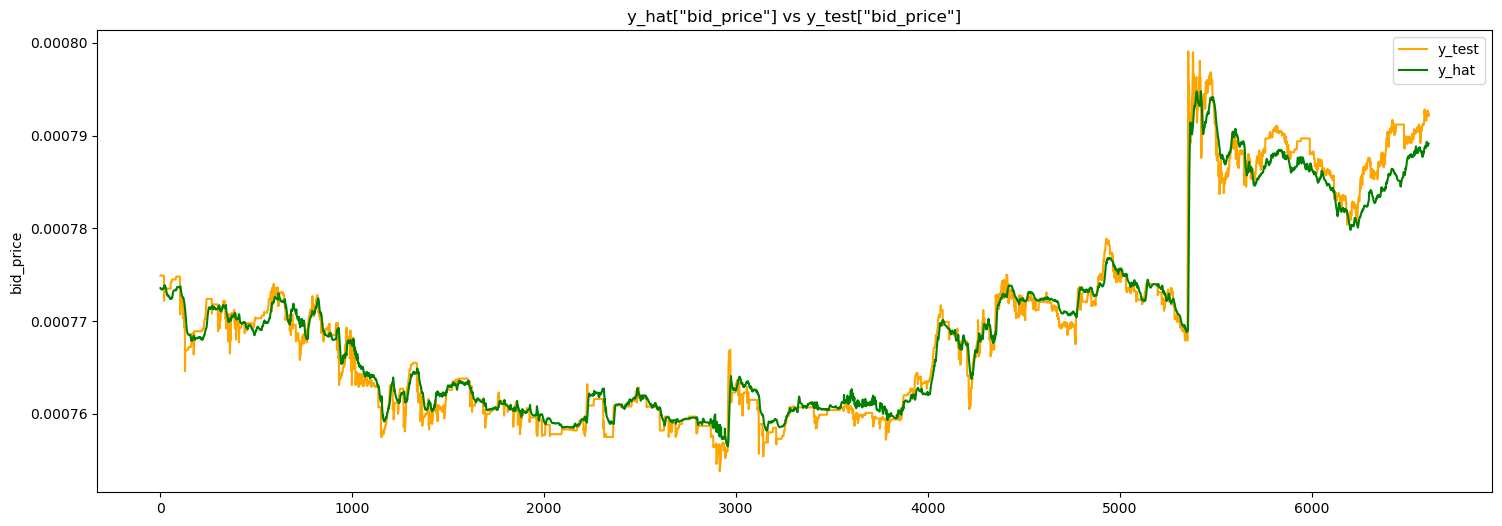

In [26]:
# visualize bid-price prediction

plt.figure(figsize=(18,6))
plt.plot(y_test['bid_price'],color='orange',label='y_test')
plt.plot(y_hat[:,3],color='green', label='y_hat')
plt.title('y_hat["bid_price"] vs y_test["bid_price"]')
plt.ylabel('bid_price')
plt.legend()
plt.show()

In [23]:
# predicting the future

def moving_test_window_preds(start, n_future_preds):
    prediction=[]
    moving_input_window=[]
    
    inputs=test.reset_index(drop=True).values
    inputs=sc.transform(inputs)
    
    moving_input_window.append(inputs[start:(start+steps), :])
    moving_input_window=np.array(moving_input_window)
    moving_input_window = np.reshape(moving_input_window, (moving_input_window.shape[0], moving_input_window.shape[1], 9))
    
    for i in range(n_future_preds):
        y_hat=model.predict(moving_input_window)
        prediction.append(y_hat[0,:])
        y_hat=y_hat.reshape(1,1,9)
        moving_input_window=np.concatenate((moving_input_window[:,1:,:], y_hat),axis=1)

    prediction = sc.inverse_transform(pd.DataFrame(prediction))
    return prediction

In [24]:
#make prediction for next 20 time steps or future instances 

n_future_preds=20
prediction=moving_test_window_preds(0,n_future_preds)

1/1 [==============================] - 0s 22ms/step


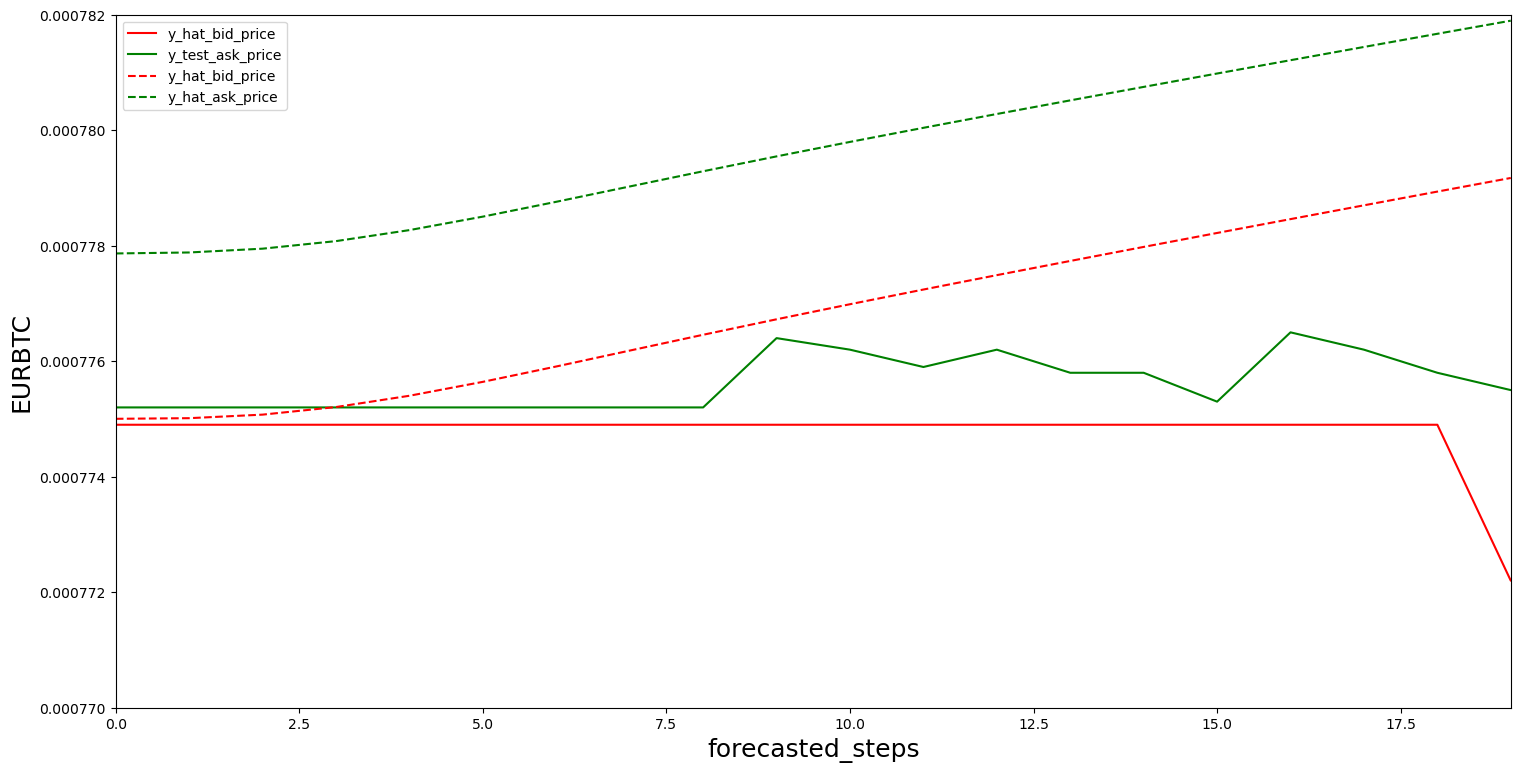

In [25]:
# plotting the actual bid and ask prices from test dataset along with predicted bid and ask price

plt.figure(figsize=(18,9))
plt.plot(y_test["bid_price"], color='red', label='y_hat_bid_price')
plt.plot(y_test["ask_price"], color='green', label='y_test_ask_price')
plt.plot(prediction[:,3],color='red', label='y_hat_bid_price',linestyle='--')
plt.plot(prediction[:,0],color='green', label='y_hat_ask_price',linestyle='--')
plt.gca().set_xlim(0,prediction.shape[0]-1)
plt.gca().set_ylim(0.00077,0.000782)
plt.xlabel('forecasted_steps', fontsize=18)
plt.ylabel('EURBTC', fontsize=18)
plt.legend()
plt.show()

In [27]:
# generating multiple prediction using moving window approach

def multiple_predictions():
    predictions=[]
    for i in range(0, test.shape[0]-steps,steps):
        y_hat=moving_test_window_preds(i,n_future_preds)
        predictions.append(y_hat)
    return predictions
predictions=multiple_predictions()

1/1 [==============================] - 0s 23ms/step


In [32]:

test_data_ask_vs_bid_price_delta_positive_predictions_only = []
prediction_data_ask_vs_bid_price_delta_positive_predictions_only = []

for i, p in enumerate(predictions):
    delta = p[:,3][n_future_preds-1]-p[:,0][0]
    if delta > 0:
        buy = y_test["ask_price"][i+steps]
        sale = y_test["bid_price"][i]
        test_data_ask_vs_bid_price_delta_positive_predictions_only.append(sale-buy)
        prediction_data_ask_vs_bid_price_delta_positive_predictions_only.append(delta)

test_data_ask__vs_bid_price_delta_cumulative_positive_predictions_only = np.cumsum(test_data_ask_vs_bid_price_delta_positive_predictions_only)
prediction_data_ask_vs_bid_price_delta_cumulative_positive_predictions_only = np.cumsum(prediction_data_ask_vs_bid_price_delta_positive_predictions_only)

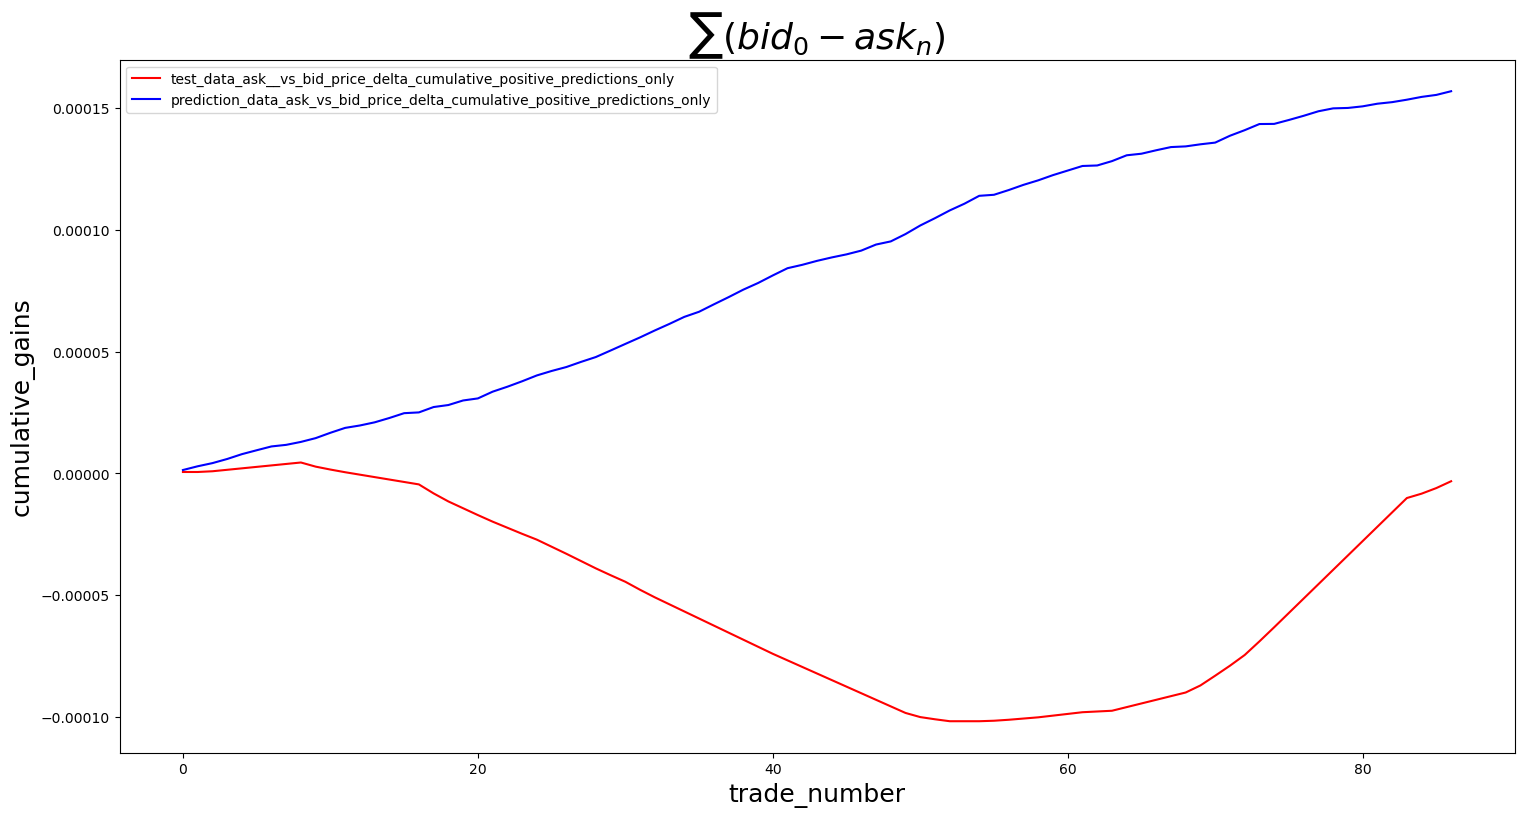

In [33]:
plt.figure(figsize = (18,9))
plt.plot(test_data_ask__vs_bid_price_delta_cumulative_positive_predictions_only, color = 'red', label='test_data_ask__vs_bid_price_delta_cumulative_positive_predictions_only')
plt.plot(prediction_data_ask_vs_bid_price_delta_cumulative_positive_predictions_only, color = 'blue', label = 'prediction_data_ask_vs_bid_price_delta_cumulative_positive_predictions_only')
plt.title(r'$\sum (bid_0 - ask_n$)', fontsize=26)
plt.xlabel('trade_number', fontsize=18)
plt.ylabel('cumulative_gains', fontsize=18)
plt.legend()
plt.show()

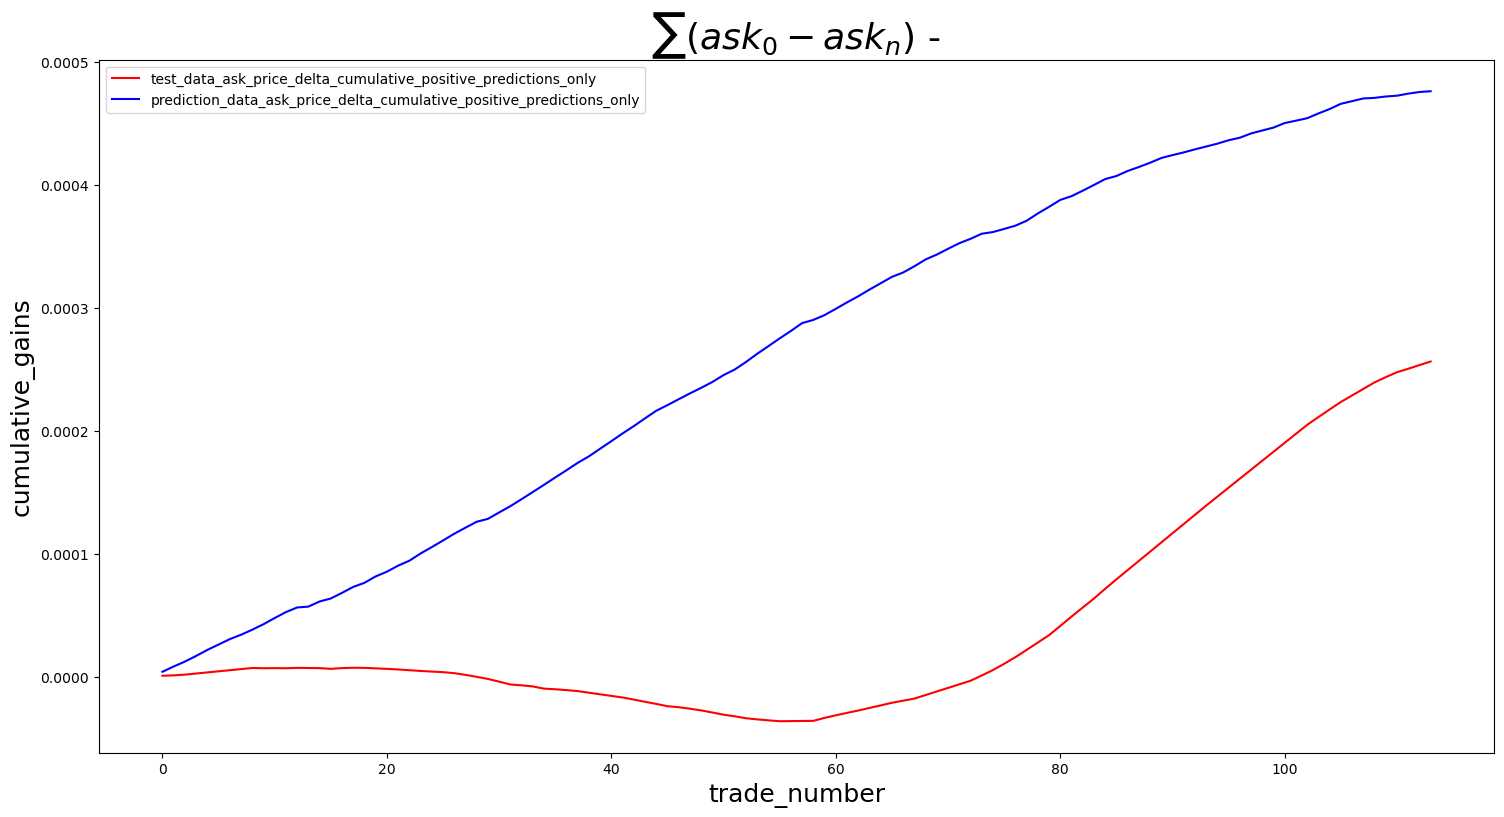

In [30]:
# plotting the cummulative gains based on differences between ask price and positive generated by model

plt.figure(figsize = (18,9))
plt.plot(test_data_ask_price_delta_cumulative_positive_predictions_only, color = 'red', label='test_data_ask_price_delta_cumulative_positive_predictions_only')
plt.plot(prediction_data_ask_price_delta_cumulative_positive_predictions_only, color = 'blue', label = 'prediction_data_ask_price_delta_cumulative_positive_predictions_only')
plt.title(r'$\sum (ask_0 - ask_n$) - ', fontsize=26)
plt.xlabel('trade_number', fontsize=18)
plt.ylabel('cumulative_gains', fontsize=18)
plt.legend()
plt.show()

In [34]:
test_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only = []
prediction_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only = []
taker_fee = 0.001

for i, p in enumerate(predictions):
    buy_predict = p[:,0][0]*(1+taker_fee)
    sell_predict = p[:,3][n_future_preds-1]*(1-taker_fee)
    delta = sell_predict - buy_predict
    if delta > 0:
        buy = y_test["ask_price"][i+steps]*(1+taker_fee)
        sale = y_test["bid_price"][i]*(1-taker_fee)
        test_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only.append(sale-buy)
        prediction_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only.append(delta)

test_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only = np.cumsum(test_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only)
prediction_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only = np.cumsum(prediction_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only)
        

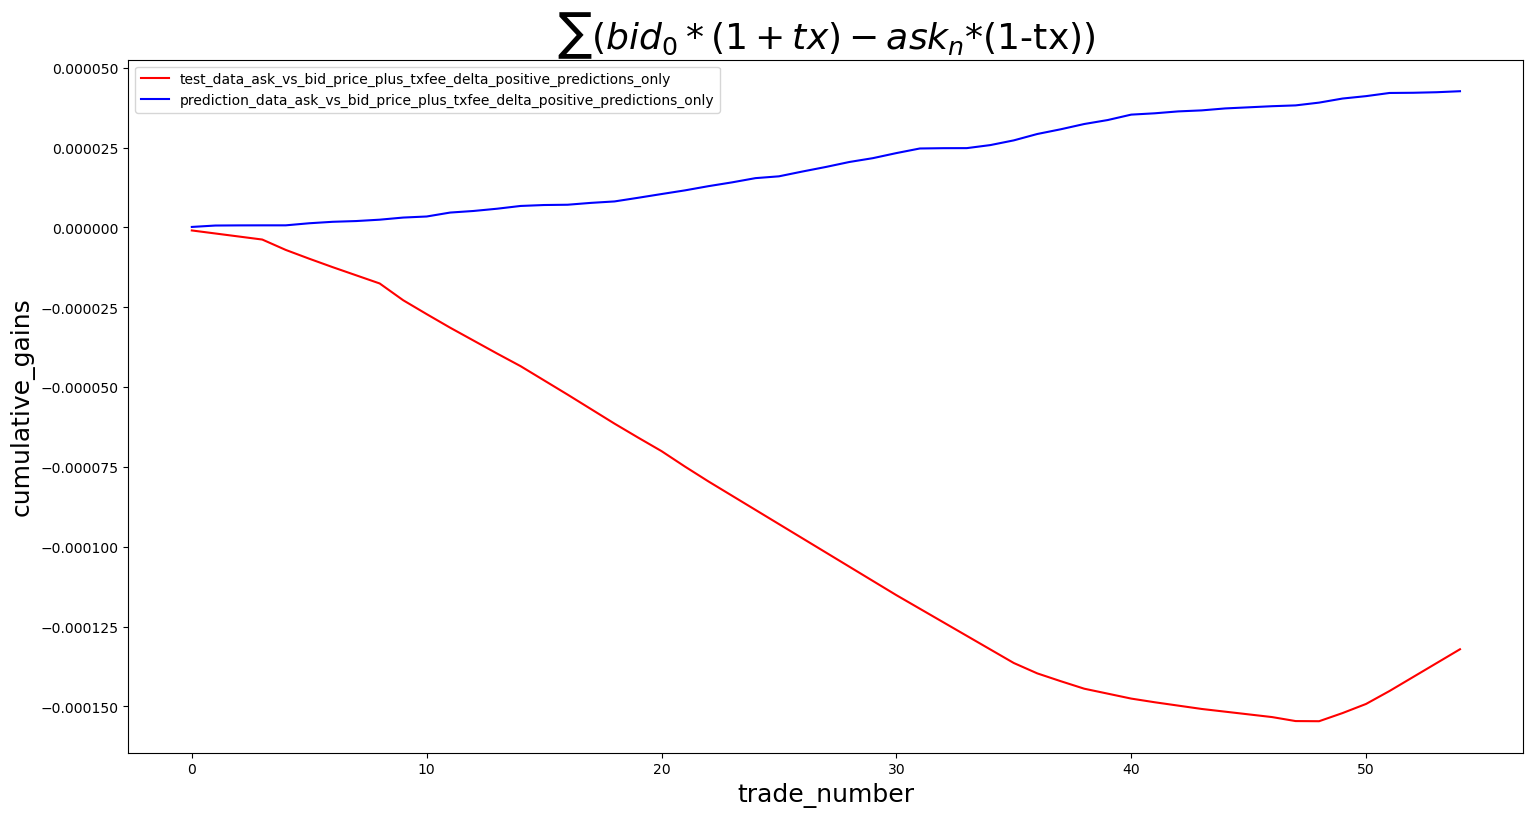

In [35]:
plt.figure(figsize = (18,9))
plt.plot(test_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only, color = 'red', label='test_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only')
plt.plot(prediction_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only, color = 'blue', label = 'prediction_data_ask_vs_bid_price_plus_txfee_delta_positive_predictions_only')
plt.title(r'$\sum (bid_0*(1+tx) - ask_n$*(1-tx))', fontsize=26)
plt.xlabel('trade_number', fontsize=18)
plt.ylabel('cumulative_gains', fontsize=18)
plt.legend()
plt.show()